### Further Topics in OLS 

1. Categorical Data
2. Nonlinear Terms
3. Binary Outcomes
4. Bias Variance Tradeoff


##### Ordinary Least Squares Regression with categorical data

The **Auto MPG** dataset contains the following variables:
- `mpg`: fuel economy (miles per gallon)
- `weight`: vehicle weight
- `origin`: country/region of origin (`usa`, `europe`, or `japan`)

In this version of the dataset, `origin` is already stored as a string. We will treat it as a **categorical** variable in the regression.

How exactly does our model handle this?

#### 1. Load the data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
auto = pd.read_csv(url)

auto.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
# Inspect the variables and data types
auto.info()


<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


## 2. Clean the data

In [4]:
# Check for missing values
auto.isna().sum()


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [5]:
# Keep complete observations for the variables used below
data = auto.dropna(subset=["mpg", "weight", "origin"]).copy()

# Rescale and center weight:
# one unit corresponds to 1,000 lb, and zero is the sample mean weight.
data["weight_1000"] = (data["weight"] - data["weight"].mean()) / 1000

data[["mpg", "weight", "weight_1000", "origin"]].head()

,mpg,weight,weight_1000,origin
0,18.0,3504,0.533575,usa
1,15.0,3693,0.722575,usa
2,18.0,3436,0.465575,usa
3,16.0,3433,0.462575,usa
4,17.0,3449,0.478575,usa


#### 3. Scatter plot: MPG versus weight

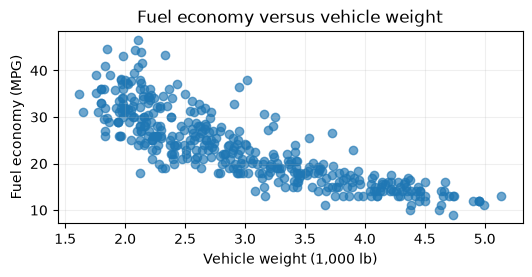

In [6]:
plt.figure(figsize=(6, 2.5))
plt.scatter(data["weight"] / 1000, data["mpg"], alpha=0.65)
plt.xlabel("Vehicle weight (1,000 lb)")
plt.ylabel("Fuel economy (MPG)")
plt.title("Fuel economy versus vehicle weight")
plt.grid(alpha=0.2)
plt.show()


#### 4. Fit an ordinary least squares regression

We use **Patsy** to translate a formula into the response vector and design matrix, and **scikit-learn** to estimate the regression coefficients.

The formula

```python
mpg ~ weight
```

represents the model

$$
MPG_i = \beta_0 + \beta_1\,weight_i + \varepsilon_i.
$$

Patsy includes an intercept column by default. Therefore, we set `fit_intercept=False` in scikit-learn to avoid fitting a second intercept.


In [11]:
from patsy import dmatrices,dmatrix
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Build response vector y and design matrix X
y, X = dmatrices("mpg ~ weight_1000", data=data, return_type="dataframe")

# Fit OLS using scikit-learn
model = LinearRegression(fit_intercept=False)
model.fit(X, y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",False
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 2)","[[23.51,-7.68]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Intercept','weight_1000']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float,0
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


#Comparing additive and interactive model variables

In [20]:
additive_mdl= smf.ols("mpg ~ weight_1000 + horsepower", data=data).fit()
additive_mdl.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     467.9
Date:                Fri, 13 Nov 2026   Prob (F-statistic):          3.06e-104
Time:                        13:21:04   Log-Likelihood:                -1121.0
No. Observations:                 392   AIC:                             2248.
Df Residuals:                     389   BIC:                             2260.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      28.4291      1.175     24.203      0.000      26.120      30.739
weight_1000    -5.7942      0.502    -11.535      0.000      -6.782      -4.807
horsepower     -0.0473      0.011     -4.267      0.000      -0.069      -0.026
==============================================================================
Omnibus:                       35.336   Durbin-Watson:                   0.858
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.973
Skew:                           0.683   Prob(JB):                     1.04e-10
Kurtosis:                       3.974   Cond. No.                         651.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [19]:

interactive_mdl= smf.ols("mpg ~ weight_1000*horsepower", data=data).fit()
interactive_mdl.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.746
Method:                 Least Squares   F-statistic:                     384.8
Date:                Fri, 13 Nov 2026   Prob (F-statistic):          7.26e-116
Time:                        13:21:01   Log-Likelihood:                -1090.7
No. Observations:                 392   AIC:                             2189.
Df Residuals:                     388   BIC:                             2205.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 31.5593      1.156     27.302      0.000      29.287      33.832
weight_1000              -10.7724      0.774    -13.921      0.000     -12.294      -9.251
horsepower                -0.0918      0.012     -7.868      0.000      -0.115      -0.069
weight_1000:horsepower     0.0536      0.007      8.054      0.000       0.040       0.067
==============================================================================
Omnibus:                       34.175   Durbin-Watson:                   0.904
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               54.522
Skew:                           0.577   Prob(JB):                     1.45e-12
Kurtosis:                       4.417   Cond. No.                         832.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:

interactive_mdl= smf.ols("mpg ~ weight_1000:horsepower", data=data).fit()
interactive_mdl.summary()

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     467.9
Date:                Fri, 13 Nov 2026   Prob (F-statistic):          3.06e-104
Time:                        13:19:52   Log-Likelihood:                -1121.0
No. Observations:                 392   AIC:                             2248.
Df Residuals:                     389   BIC:                             2260.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      28.4291      1.175     24.203      

### Estimated coefficients and model fit

In [ ]:
coefficients = pd.Series(model.coef_.ravel(), index=X.columns)

print(f"Intercept: {coefficients['Intercept']:.4f}")
print(f"Slope per 1,000-lb increase in weight: {coefficients['weight_1000']:.6f}")
print(f"R-squared: {model.score(X, y):.4f}")


Intercept: 23.5146
Slope per 1,000-lb increase in weight: -7.676610
R-squared: 0.6918


#### 5. Plot the fitted regression line

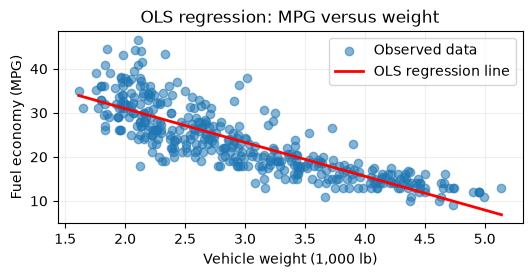

In [ ]:
# Predictions for the observations
data["predicted_mpg"] = model.predict(X)

# Sort by weight so that the fitted line is drawn in the right order
plot_data = data.sort_values("weight_1000")

plt.figure(figsize=(6, 2.5))
plt.scatter(data["weight"] / 1000, data["mpg"], alpha=0.55, label="Observed data")
plt.plot(
    plot_data["weight"] / 1000,
    plot_data["predicted_mpg"],
    color="red",
    linewidth=2,
    label="OLS regression line"
)
plt.xlabel("Vehicle weight (1,000 lb)")
plt.ylabel("Fuel economy (MPG)")
plt.title("OLS regression: MPG versus weight")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


#### 6. Multiple regression: include origin

Patsy uses `C(origin)` to indicate that `origin` is categorical. It automatically creates the required dummy variables, using one category as the reference group.

The model is

$$
MPG_i = \beta_0 + \beta_1\,weight_i
       + \text{origin effects} + \varepsilon_i.
$$


In [23]:
# Treat origin as categorical
y_origin, X_origin = dmatrices(
    "mpg ~ weight_1000 + C(origin)",
    data=data,
    return_type="dataframe"
)

model_origin = LinearRegression(fit_intercept=False)
model_origin.fit(X_origin, y_origin)

print("Design-matrix columns:")
X_origin.head() 


Design-matrix columns:


,Intercept,C(origin)[T.japan],C(origin)[T.usa],weight_1000
0,1.0,0.0,1.0,0.533575
1,1.0,0.0,1.0,0.722575
2,1.0,0.0,1.0,0.465575
3,1.0,0.0,1.0,0.462575
4,1.0,0.0,1.0,0.478575


In [ ]:
print("\nEstimated coefficients:")
print(pd.Series(model_origin.coef_.ravel(), index=X_origin.columns))

print(f"\nR-squared: {model_origin.score(X_origin, y_origin):.4f}")


Estimated coefficients:
Intercept             24.048732
C(origin)[T.japan]     1.139963
C(origin)[T.usa]      -1.215472
weight_1000           -7.023439
dtype: float64

R-squared: 0.7015


## 2. Nonlinear Terms

So far, we have assumed that the relationship between vehicle weight and fuel economy is linear:

$$
MPG_i = \beta_0 + \beta_1 weight_i + \varepsilon_i.
$$

But the scatter plot suggests that the relationship may not be perfectly linear. One simple way to allow for curvature is to add a **quadratic term**:

$$
MPG_i = \beta_0 + \beta_1 weight_i
       + \beta_2 weight_i^2 + \varepsilon_i.
$$

This is still a linear regression model: it is linear in the unknown coefficients
$\beta_0, \beta_1, \beta_2$. Only the predictor enters nonlinearly.

In a Patsy formula, use `I(weight**2)` to tell Patsy to calculate the square of `weight`. The `I()` means “interpret this as ordinary arithmetic.”

Here, `weight_1000` is vehicle weight, centered at its sample mean and measured in units of 1,000 pounds. Centering makes the intercept correspond to the expected MPG at the average vehicle weight. Scaling makes the coefficients easier to read.


**A note about the shape:** rescaling and centering weight changes the numerical values and interpretation of the coefficients, but it does not change the fitted curve or its predictions. If the quadratic curve bends in an implausible way or predicts negative MPG near the heaviest cars, that is a limitation of this global quadratic specification—not a plotting or scaling error. A quadratic is a simple teaching example, not necessarily the best predictive model for this relationship.

In [24]:
from patsy import dmatrices
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Quadratic regression: same observations and response as the linear model
y_quad, X_quad = dmatrices(
    "mpg ~ weight_1000 + I(weight_1000**2)",
    data=data,
    return_type="dataframe"
)

# Patsy includes the intercept, so disable sklearn's extra intercept.
model_quad = LinearRegression(fit_intercept=False)
model_quad.fit(X_quad, y_quad.values.ravel())

#print("Design-matrix columns:", X_quad.columns.tolist())
print("\\nEstimated coefficients:")
print(pd.Series(model_quad.coef_.ravel(), index=X_quad.columns))

r2_quad = r2_score(y_quad.values.ravel(), model_quad.predict(X_quad))
print(f"Quadratic model R-squared: {r2_quad:.4f}")


\nEstimated coefficients:
Intercept              22.286674
weight_1000            -8.444697
I(weight_1000 ** 2)     1.716527
dtype: float64
Quadratic model R-squared: 0.7148


### Compare the linear and quadratic models

The quadratic model has an additional parameter, so its in-sample \(R^2\) cannot be lower than that of the linear model. A better fit alone does not necessarily mean that the quadratic model will predict better on new data.

**Important OLS property:** These are nested models fitted to the same observations, with the same response and an intercept. The linear model is the special case of the quadratic model in which the squared-term coefficient is zero. Therefore, adding `weight_1000**2` cannot reduce the in-sample $R^2$. The code below refits both models on the same rows and checks this property explicitly.



In [ ]:
# Refit the linear model on exactly the same observations as the quadratic model
y_linear, X_linear = dmatrices(
    "mpg ~ weight_1000",
    data=data,
    return_type="dataframe"
)

model_linear = LinearRegression(fit_intercept=False)
model_linear.fit(X_linear, y_linear.values.ravel())

r2_linear = r2_score(y_linear.values.ravel(), model_linear.predict(X_linear))
r2_quad = r2_score(y_quad.values.ravel(), model_quad.predict(X_quad))


print(f"Linear model R-squared:    {r2_linear:.4f}")
print(f"Quadratic model R-squared: {r2_quad:.4f}")
print(f"Change in R-squared:       {r2_quad - r2_linear:+.4f}")


Linear model R-squared:    0.6918
Quadratic model R-squared: 0.7148
Change in R-squared:       +0.0230


### Plot the quadratic regression curve

To draw a smooth fitted curve, we create a sequence of weight values and ask the fitted model for a prediction at each value.

We use Patsy's `design_info` from the original design matrix when constructing the new design matrix. This ensures that the prediction data have exactly the same columns (including the intercept and squared-weight term) as the data used to fit the model.

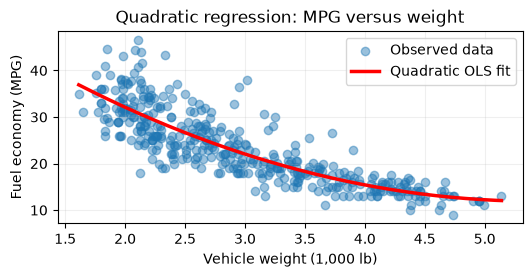

In [ ]:
# Create an evenly spaced grid in the centered, scaled weight variable
weight_grid = pd.DataFrame({
    "weight_1000": np.linspace(data["weight_1000"].min(), data["weight_1000"].max(), 200)
})

# Reuse the exact Patsy design specification used to fit the model
from patsy import build_design_matrices

X_grid_quad = build_design_matrices(
    [X_quad.design_info],
    weight_grid,
    return_type="dataframe"
)[0]

predicted_grid = model_quad.predict(X_grid_quad).ravel()

# Convert centered/scaled weight back to 1,000-lb units for the x-axis.
# IMPORTANT: the observed points and fitted curve must use the same x scale.
weight_grid_x = weight_grid["weight_1000"] + data["weight"].mean() / 1000

plt.figure(figsize=(6, 2.5))
plt.scatter(
    data["weight"] / 1000, data["mpg"],
    alpha=0.45, label="Observed data"
)
plt.plot(
    weight_grid_x, predicted_grid,
    color="red", linewidth=2.5, label="Quadratic OLS fit"
)
plt.xlabel("Vehicle weight (1,000 lb)")
plt.ylabel("Fuel economy (MPG)")
plt.title("Quadratic regression: MPG versus weight")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


**Interpretation:** The coefficient of `weight_1000` is not the slope at every weight. In the quadratic model, the slope with respect to a 1,000-lb increase depends on the current centered weight:

$$
\frac{d\,MPG}{d\,weight_{1000}}
= \beta_1 + 2\beta_2 weight_{1000}.
$$

The coefficient of the squared term describes the curvature. A positive coefficient gives a U-shaped curve; a negative coefficient gives an inverted U-shaped curve.

## 3. Binary Outcomes

So far, the response variable (`mpg`) has been continuous. Sometimes we want to predict a **binary outcome**, for example whether a car has relatively good fuel economy.

For this example, define a car as having high fuel economy if its highway-independent fuel economy measure `mpg` is at least 25 MPG:

$$
high\_mpg_i =
\begin{cases}
1 & \text{if } mpg_i \geq 25,\\
0 & \text{otherwise.}
\end{cases}
$$

This threshold is chosen for illustration; it is not a universal definition of an efficient car.

A common model for a binary response is **logistic regression**. It models the log-odds of the event as a linear function of the predictors:

$$
\log\left(\frac{P(Y_i=1\mid x_i)}
{1-P(Y_i=1\mid x_i)}\right)
= \beta_0 + \beta_1 x_i.
$$

The predicted probabilities therefore lie between 0 and 1. We will again use Patsy to construct the design matrix and scikit-learn to fit the model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create a binary outcome: 1 if mpg is at least 25, and 0 otherwise
data["high_mpg"] = (data["mpg"] >= 25).astype(int)

print(data["high_mpg"].value_counts().sort_index())


high_mpg
0    229
1    169
Name: count, dtype: int64


### Fit a logistic regression using Patsy and scikit-learn

In [ ]:
# Patsy constructs the response and design matrix
y_binary, X_binary = dmatrices(
    "high_mpg ~ weight_1000",
    data=data,
    return_type="dataframe"
)

# Fit logistic regression
# Patsy already includes an intercept, so fit_intercept=False
logit_model = LogisticRegression(fit_intercept=False)
logit_model.fit(X_binary, y_binary.values.ravel())

print("Estimated coefficients:")
print(pd.Series(logit_model.coef_.ravel(), index=X_binary.columns))


Estimated coefficients:
Intercept     -1.043377
weight_1000   -3.458475
dtype: float64


### Predicted probabilities

Unlike OLS, logistic regression predicts probabilities between 0 and 1. We can plot the estimated probability that a car has at least 25 MPG against its weight.

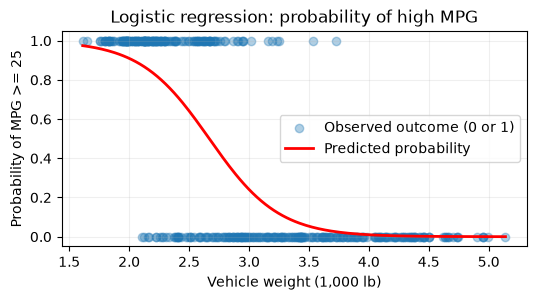

In [ ]:
# Predict probabilities over a grid of centered, scaled weights
weight_grid = pd.DataFrame({
    "weight_1000": np.linspace(data["weight_1000"].min(), data["weight_1000"].max(), 200)
})
X_grid_logit = dmatrix(
    "weight_1000",
    data=weight_grid,
    return_type="dataframe"
)
probability_grid = logit_model.predict_proba(X_grid_logit)[:, 1]

# Convert to the same 1,000-lb x-axis scale used for the observed data
weight_grid_x = weight_grid["weight_1000"] + data["weight"].mean() / 1000

plt.figure(figsize=(6, 2.8))
plt.scatter(
    data["weight"] / 1000, data["high_mpg"],
    alpha=0.35, label="Observed outcome (0 or 1)"
)
plt.plot(
    weight_grid_x, probability_grid,
    color="red", linewidth=2, label="Predicted probability"
)
plt.xlabel("Vehicle weight (1,000 lb)")
plt.ylabel("Probability of MPG >= 25")
plt.title("Logistic regression: probability of high MPG")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### Turn probabilities into classifications

To obtain a predicted class, we choose a probability threshold. The default threshold in scikit-learn's `predict()` is 0.5:

- predict class 1 if the estimated probability is at least 0.5;
- predict class 0 otherwise.

We can then evaluate the classifications using a confusion matrix and accuracy. These are **training-set** results here, because we have not yet separated the data into training and test sets.

In [ ]:
# Predicted classes using the default 0.5 threshold
y_pred = logit_model.predict(X_binary)

print("Confusion matrix:")
print(confusion_matrix(y_binary.values.ravel(), y_pred))

print(f"Accuracy: {accuracy_score(y_binary.values.ravel(), y_pred):.3f}")

print("\nClassification report:")
print(classification_report(y_binary.values.ravel(), y_pred, zero_division=0))


Confusion matrix:
[[195  34]
 [ 26 143]]
Accuracy: 0.849

Classification report:
              precision    recall  f1-score   support

         0.0       0.88      0.85      0.87       229
         1.0       0.81      0.85      0.83       169

    accuracy                           0.85       398
   macro avg       0.85      0.85      0.85       398
weighted avg       0.85      0.85      0.85       398



**Important distinction:** Logistic regression is designed for binary outcomes. An OLS regression with a 0/1 response (the *linear probability model*) is also possible, but its predictions are not constrained to the interval [0, 1], and its error variance is not constant. Logistic regression addresses the probability-boundary issue by using the logistic function.

For a fair assessment of predictive performance, split the data into training and test sets (or use cross-validation) rather than evaluating only on the data used to fit the model.

## 4. Optional exercises for students

### Categorical predictors
1. Interpret the slope in the simple regression. What does it say about the association between vehicle weight and fuel economy?
2. What does the R-squared value tell you?
3. Does adding `origin` improve the model's fit? Compare the two R-squared values.
4. Which origin category is the reference category in the multiple regression? How should the dummy-variable coefficients be interpreted?
5. Try adding `horsepower` to the model. Does the estimated coefficient for `weight` change?

### Nonlinear terms
6. Does the quadratic model fit the observed data better than the linear model, in terms of training R-squared?
7. What does the sign of the coefficient of `I(weight**2)` tell you about the curvature?
8. Why is the coefficient of `weight` in the quadratic model not the slope for every car?

### Binary outcomes
9. What proportion of cars in this dataset have `high_mpg = 1`?
10. How does the predicted probability of high fuel economy change with vehicle weight?
11. What does the 0.5 classification threshold mean? What would happen if we used a different threshold?
12. Why should we evaluate predictive performance on a test set rather than only on the training data?

**Hint:** Patsy formulas can include several predictors, for example:

```python
"mpg ~ weight + horsepower + C(origin)"
```
